# **MODULE 9 — SHORT-TIME FOURIER TRANSFORM (STFT) 🎵**

**Core DSP Concept**

**Essential for Speech AI**

In Module 8, we learned how FFT converts a signal from the time domain into the frequency domain.

But there is a problem when we apply an ordinary FFT to an entire speech recording.

**It tells us which frequencies are present, but it does not tell us exactly when those frequencies occur.**

This is why we need the **Short-Time Fourier Transform (STFT)**.

STFT is one of the most important concepts in speech processing because it allows us to study how the frequency content of audio changes over time.

It is widely used in:

- Automatic Speech Recognition (ASR)
- Speech Emotion Recognition (SER)
- Speech enhancement and noise reduction
- Audio classification
- Speaker recognition
- Spectrogram-based deep learning models

---

## **9.1 Limitations of Global FFT**

Let's imagine recording someone saying:

**"HELLO"**

The recording contains multiple speech sounds:

- /h/
- /ə/
- /l/
- /oʊ/

Each sound has different acoustic characteristics.

For example:

- Vowels generally have strong periodic components and identifiable formant structures.
- Fricatives such as /s/ contain noise-like high-frequency energy.
- Different vowels have different formant frequencies.
- Pitch can change during speech.

Now imagine applying one FFT to the entire recording.

The FFT combines frequency information from the whole recording into one spectrum.

![Speech Processing](https://images.openai.com/static-rsc-4/WyM1cSELMtRfIVx4PpoFczYS6_Am9oP54esI8_DNMAbM46qaN3oYhMdVyQhvGnR9eM1NHnfVIJdai7JFZd4k3xHgvTzDbbztuJzXbVrtxp8tatfWVLSZ2tJxK720rH88n8hKvTsgYFvINvUWXKV2E3YU8pSMsjp63Y8U5bNWPMo?purpose=inline)

Reference: [Aman's AI Journal — Speech Processing](https://aman.ai/primers/ai/speech-processing/?utm_source=chatgpt.com)

The problem:

Suppose a 1-second recording contains:

| Time | Speech sound |
|---|---|
| 0–0.25 s | Vowel A |
| 0.25–0.50 s | Consonant |
| 0.50–0.75 s | Vowel B |
| 0.75–1.00 s | Vowel C |

A global FFT may reveal frequency components from all these sounds, but it cannot show clearly which components belong to which time interval.

**Global FFT loses the time-localization information.**

This is its major limitation for speech analysis.

---

## **9.2 Non-Stationary Signals**

Before understanding STFT, we need to understand *stationarity*.

A signal is called stationary when its statistical characteristics remain approximately constant over time.

Examples of characteristics include:

- Mean
- Variance
- Frequency distribution

A pure, steady sinusoid is a simple example of a stable signal.

Human speech, however, is generally **non-stationary**.

Its properties change continuously as we speak.

For example:

- Pitch changes.
- Amplitude changes.
- Frequency distribution changes.
- Phonemes change.
- Formants move.
- Voiced and unvoiced regions alternate.

![Non-stationary audio signals](https://images.openai.com/static-rsc-4/42K1zf691zXJPE6-lWPIyr27D0a-rtziQdyjSST6aa8d_F8SyOu4_v0BIMUH4SlYXT4dlzgSC4r6mIWIoe56xZ6N82JtxDzCBUuCH9e7gXBy7KTKNB0u246wQqtK4hHu5FEhoR4msRVaT6kgIJrtzA_uXA1ja3qVsxsvLOuNdiE?purpose=inline)

Reference: [Exploring the Short-Time Fourier Transform — Medium](https://medium.com/%40ongzhixuan/exploring-the-short-time-fourier-transform-analyzing-time-varying-audio-signals-98157d1b9a12?utm_source=chatgpt.com)

### **Why does this matter?**

An entire speech recording cannot always be treated as one stationary signal.

However, over a sufficiently short interval, speech can often be approximated as quasi-stationary.

This is the key assumption behind traditional short-time speech analysis.

**Quasi-stationary means that the signal changes relatively little within a short analysis frame.**

---

## **9.3 Short-Time Analysis**

Instead of analyzing the entire audio recording at once, we divide it into smaller sections.

Each section is called a **frame**.

For example, suppose we have a 1-second recording sampled at 16 kHz.

Total samples:

$$
N=16000
$$

Instead of applying FFT to all 16,000 samples at once, we can analyze smaller frames of 400 samples.

At 16 kHz:

$$
\text{Frame duration}=\frac{400}{16000}
$$

$$
=0.025s=25ms
$$

So each frame represents 25 milliseconds of audio.

We calculate an FFT for each frame separately.

![Frame-based speech processing](https://images.openai.com/static-rsc-4/H6huHqN3PIEtYacBf5Vnt0KoHE9-HSB8iddYwZBwY1VAjpHtaB_NWn4STHFgOBkVkKigTaXOTmwdcs3xJTE5eg7kCbHTI-baHdm2ieUxw9fc64YmZB2w5t34zaZ-dRXjPn0d1WaV36v8qh9LhKvOcYrSj1e5srxpwuG-gbwdvbo?purpose=inline)

Reference: [Voiceprint System Development — SlideServe](https://www.slideserve.com/debbie/voiceprint-system-development-design-implement-test-unique-voiceprint-biometric-system?utm_source=chatgpt.com)

Now we can observe how the frequency content changes from one frame to another.

This is the fundamental idea of STFT.

---

## **9.4 Frame-Based Audio Processing**

Frame-based processing is a technique in which a continuous audio signal is divided into smaller segments for analysis.

Each frame is processed independently or in relation to neighboring frames.

Typical operations include:

1. Extract a frame from the audio signal.
2. Apply a window function.
3. Calculate the FFT.
4. Store the frequency representation.
5. Move to the next frame.
6. Repeat until the recording is processed.

![Frame-based audio processing](https://images.openai.com/static-rsc-4/gZ1nLltAGoT5XY_F5Z3z2DtEJIhzRvulDbbAydYd9Ko7jK_vFr7-b-XNBcfFZlbCn48no3-sbPBCK6CbSfn4K7b5DL6DNXW0t3G8hCsdhAwcEKQiIzwGcLK2X-D7CJE5RuRofg1rPxhwpaFuqM6dxeoBCHaDJCOWN8g-t2u52DM?purpose=inline)

Reference: [Speech Emotion Recognition Using Deep Learning — MDPI](https://www.mdpi.com/2076-3417/14/4/1553?utm_source=chatgpt.com)

### **Example**

Suppose:

- Sampling rate = 16,000 Hz
- Frame length = 400 samples
- Frame duration = 25 ms
- Hop length = 160 samples
- Hop duration = 10 ms

The first frame contains samples:

$$
0 \text{ to } 399
$$

The second frame contains:

$$
160 \text{ to } 559
$$

The third frame contains:

$$
320 \text{ to } 719
$$

Notice that the frames overlap.

We'll understand why in the next section.

---

## **9.5 Window Length**

**Window length** is the number of samples included in each frame.

It determines how much audio is analyzed at one time.

For example, at a sampling rate of 16 kHz:

| Window length | Duration |
|---|---|
| 160 samples | 10 ms |
| 256 samples | 16 ms |
| 320 samples | 20 ms |
| 400 samples | 25 ms |
| 512 samples | 32 ms |
| 640 samples | 40 ms |

The relationship is:

$$
T_w=\frac{N_w}{f_s}
$$

Where:

- $T_w$ = Window duration
- $N_w$ = Number of samples in the window
- $f_s$ = Sampling rate

### **What happens if we change window length?**

**Short window:**

- Captures rapid changes in speech more precisely.
- Gives better time localization.
- Has coarser frequency resolution.

**Long window:**

- Gives finer frequency resolution.
- Helps distinguish nearby frequency components.
- Can combine different speech sounds within the same frame.

![STFT window length](https://images.openai.com/static-rsc-4/9KHS_3vSqYOLtGkgX1Mr4vjHdtlb7VoXoJDMmnMyeCMjH4Fr1MR7eGwOWvJRSqNk9ElJ9--pCnLROGrAhN2Rpg8wO_N2PwYdJHO7h62_zblzJMJK9sM5swBnRoBaJEb2zhSZVAXqZaBG2_XLU0B7T053piWnuFko905gjc5MW8w?purpose=inline)

Reference: [Short-Time Fourier Transform — SlideServe](https://www.slideserve.com/lavallee/introduction-to-the-short-time-fourier-transform-stft-powerpoint-ppt-presentation?utm_source=chatgpt.com)

This is an important design decision in speech processing.

---

## **9.6 Hop Length**

Hop length is the number of samples by which we move forward when extracting the next frame.

It determines the distance between consecutive frame starting positions.

Suppose:

- Window length = 400 samples
- Hop length = 160 samples

Then:

| Frame | Starting sample | Ending sample |
|---|---:|---:|
| 1 | 0 | 399 |
| 2 | 160 | 559 |
| 3 | 320 | 719 |
| 4 | 480 | 879 |
| 5 | 640 | 1039 |

The hop length is 160 samples.

At 16 kHz:

$$
T_h=\frac{160}{16000}=0.01s
$$

Therefore, a new frame begins every 10 milliseconds.

### **Window length vs Hop length**

| Parameter | Meaning |
|---|---|
| Window length | Number of samples inside each frame |
| Hop length | Number of samples moved before extracting the next frame |

**Remember:** Window length controls the analysis interval. Hop length controls how frequently we perform the analysis.

---

## **9.7 Overlapping Frames**

When hop length is smaller than window length, consecutive frames overlap.

For example:

- Window length = 400 samples
- Hop length = 160 samples

Overlap:

$$
N_{\text{overlap}}=400-160=240
$$

Overlap percentage:

$$
\text{Overlap \%}=
\frac{N_w-N_h}{N_w}\times100
$$

$$
=\frac{400-160}{400}\times100
$$

$$
=60\%
$$

![Overlapping speech frames](https://images.openai.com/static-rsc-4/Bq5y_zEqzl6Hs0ddHi0yxGqY2tNRsFYpqj3-rKIJy5WflNkylZ7wO3F66sl76Ry5Mg3DWMdlTlzOcbUobgTcNGdRHitoPmJpEU-VtQfgIO97zvAOsw8X_IyTsSfJogA-GqatrB1mch6WVxtXzC6Qg87IwOzGsa-d5NZlkrkQhkM?purpose=inline)

Reference: [Speech Recognition — Feature Extraction MFCC & PLP — Medium](https://jonathan-hui.medium.com/speech-recognition-feature-extraction-mfcc-plp-5455f5a69dd9?utm_source=chatgpt.com)

### **Why do we use overlapping frames?**

Imagine analyzing speech with non-overlapping 25 ms frames.

A sound transition might occur right at the boundary between two frames.

This can make the analysis sensitive to where the frames begin and end.

Overlapping frames help by:

- Providing more frequent frequency observations.
- Capturing transitions more smoothly.
- Reducing the chance of missing short events between analysis points.
- Producing smoother time-frequency representations.

Common speech-processing configurations use window durations around 20–30 ms and hop durations around 10 ms. These are useful starting points, not universal rules.

---

## **9.8 Windowing**

When we extract a frame from an audio recording, we are selecting only a small portion of the signal.

Imagine cutting a continuous waveform at two arbitrary points.

At the frame boundaries, the selected signal may not join smoothly with its neighboring samples outside the frame.

This can introduce artificial discontinuities when we calculate the FFT.

The result is called **spectral leakage**.

### **What is spectral leakage?**

Ideally, a pure sinusoid at one frequency would produce energy concentrated at its corresponding frequency.

But if we analyze a finite segment that does not contain an integer number of cycles, the abrupt boundaries can spread energy into neighboring frequency bins.

This spreading is spectral leakage.

![Spectral leakage](https://images.openai.com/static-rsc-4/jhR3H0dn5N5Lrue_N2s-7yBkvovLK4gxPfG0Pqwvqa88L1lsyIKIzYtvIvJYQ3yWToSl0M3EzolxmRVyWiC4S5byYEvg3lRLSobdaOKKoZovvfLbi3S7Iq59YuzBYsdDvHtO57GLw44sB1YBb3wV7dCo0pIk4MPANRIZDvigZ3o?purpose=inline)

Reference: [Time and Frequency Domain Analysis — MDPI](https://www.mdpi.com/1424-8220/25/16/5161?utm_source=chatgpt.com)

### **Solution: Window functions**

A window function gradually changes the amplitude of samples near the frame boundaries.

Instead of treating every sample equally, it reduces the contribution of samples near the edges.

Mathematically:

$$
x_w[n]=x[n]w[n]
$$

Where:

- $x[n]$ = Original frame
- $w[n]$ = Window function
- $x_w[n]$ = Windowed frame

The window reduces boundary discontinuities and helps control spectral leakage.

However, it does not eliminate leakage completely.

---

## **9.9 Hann Window**

The Hann window is one of the most widely used window functions in audio processing.

Its equation is:

$$
w[n]=\frac{1}{2}
\left(
1-\cos\left(\frac{2\pi n}{N-1}\right)
\right)
$$

For:

$$
0\leq n\leq N-1
$$

### **Characteristics**

- Starts at zero.
- Gradually increases toward the middle.
- Gradually decreases toward zero at the end.
- Reduces spectral leakage compared with a rectangular window.
- Has good general-purpose frequency-analysis characteristics.

![Hann window](https://images.openai.com/static-rsc-4/7Ni-UjAfUHP7m06wGEWX31SvNnuo-G5HAEgpEw5oiObYkELPA1h7TWHH95duwufwZIUYXxxf-nMP-_hskA5C8yOw_PNQqUfSR3-FOrzCRRyr0R20eLB7eeu2NOL1OllfMO-XDuQHIx-oJRK2zkgUqb_Fv4hYBzjgT8MTHTf6QJc?purpose=inline)

Reference: [Short-Time Analysis of Speech and Audio Signals — Aalto University](https://speechprocessingbook.aalto.fi/Representations/Short-time_analysis.html?utm_source=chatgpt.com)

### **Python implementation**

```python
import numpy as np
import matplotlib.pyplot as plt

N = 400

hann_window = np.hanning(N)

plt.figure(figsize=(10, 4))
plt.plot(hann_window)

plt.title("Hann Window")
plt.xlabel("Sample Index")
plt.ylabel("Window Amplitude")

plt.grid()
plt.show()
```

---

## **9.10 Hamming Window**

The Hamming window is another commonly used window in speech processing.

Its equation is:

$$
w[n]=0.54-
0.46\cos\left(\frac{2\pi n}{N-1}\right)
$$

### **Characteristics**

- Does not reach exactly zero at its endpoints.
- Reduces spectral leakage.
- Has a different balance between the main spectral lobe and side lobes compared with Hann.
- Has historically been widely used in speech analysis.

![Hamming window](https://images.openai.com/static-rsc-4/m7sMq2YVUakQMrJe5TzVT7U6OyazeYyhZL7XEg0cU-dXwdFz-A6W6N5YErQTRW_z_HJAScktaAvNsKzWVB4nEJLj6lZGKVy0aLHr4pHg-zVh8DFT-N7N9JiHEO6-HQHPfxJ1_BCjK4k0c8q40gakLkW8OXBPAF3BkiE3dnZtUvk?purpose=inline)

Reference: [Hamming Window — Wikimedia Commons](https://commons.wikimedia.org/wiki/File%3AWindow_function_%28hamming%29.png?utm_source=chatgpt.com)

### **Python implementation**

```python
hamming_window = np.hamming(N)

plt.figure(figsize=(10, 4))

plt.plot(hann_window, label="Hann")
plt.plot(hamming_window, label="Hamming")

plt.title("Hann vs Hamming Window")
plt.xlabel("Sample Index")
plt.ylabel("Window Amplitude")

plt.legend()
plt.grid()
plt.show()
```

### **Hann vs Hamming**

| Feature | Hann | Hamming |
|---|---|---|
| Endpoints | Zero | Non-zero |
| Main purpose | Reduce leakage | Reduce leakage |
| Shape | Smooth taper to zero | Taper with non-zero endpoints |
| Common use | General spectral analysis | Speech and spectral analysis |

Both are useful. Neither is universally better; the choice depends on the analysis objective.

---

## **9.11 Short-Time Fourier Transform (STFT)**

Now we can bring all the concepts together.

The **Short-Time Fourier Transform** calculates the Fourier Transform of successive short, windowed frames of a signal.

Instead of calculating one FFT for the entire recording, STFT calculates a sequence of FFTs.

Its discrete-time representation is:

$$
X(m,k)=
\sum_{n=0}^{N-1}
x[n+mH]w[n]e^{-j2\pi kn/N}
$$

Where:

- $x[n]$ = Original audio signal
- $w[n]$ = Window function
- $N$ = Window length / FFT length in this expression
- $H$ = Hop length
- $m$ = Frame index
- $k$ = Frequency-bin index

Here is what happens:

1. Extract the first frame.
2. Multiply it by a window function.
3. Calculate its FFT.
4. Move forward by the hop length.
5. Extract the next frame.
6. Repeat the process.

![STFT representation](https://images.openai.com/static-rsc-4/fbVVuuS1ojNzeybq53ervnyvp0XNecBIur-8G6mGaNYSf1V4mjCpYbTKWotXoJ881XI369u04I8nZQV5IbjDWK1v4-rElZgiRAIFKmBtCRnp_PVk2RE4S3I_NoqCVbixiQn_077cYzAZ1mv5Qe-MiwMmhmwjS_C3Cj7Sj4_DOUg?purpose=inline)

Reference: [Resonators — John Hartquist](https://johnhartquist.com/resonators?utm_source=chatgpt.com)

The result is a two-dimensional time-frequency representation.

- One dimension represents time.
- The other represents frequency.
- Each value represents a complex frequency component for a particular frame.

**Important implementation detail:** In practical STFT implementations, the FFT length can be different from the window length. Zero-padding can increase the number of displayed frequency bins, but it does not create additional physical frequency resolution.

---

## **9.12 Magnitude STFT**

The STFT produces complex-valued frequency components.

The magnitude STFT is:

$$
M(m,k)=|X(m,k)|
$$

It represents the magnitude of each frequency component at each time frame.

In Python:

```python
magnitude_stft = np.abs(stft)
```

### **Why is magnitude STFT useful?**

It allows us to observe how frequency strength changes over time.

For example:

- Strong vowel harmonics may appear as horizontal bands.
- Fricatives may appear as broadband energy.
- Silence appears as low-energy regions.

![Magnitude STFT](https://images.openai.com/static-rsc-4/e7ZmXqL0UFYJv7tHZxq92L9GBq7C2ayCbfX2ICFXfDOjpDot_Ne850Hx8HccWap2Jm29mlfzoAQTI44QQ5cplFyzGpPCBfFUVWcIFa5pd6dOmhVtH8GXBQtIpyf7FK69Q9UUICqWUw5Tn8rkm81uCkic90U-TEAJ_JUaBsDtacY?purpose=inline)

Reference: [Audio AI — Habr](https://habr.com/ru/articles/441090/?utm_source=chatgpt.com)

---

## **9.13 Power STFT**

Power STFT is calculated by squaring the magnitude:

$$
P(m,k)=|X(m,k)|^2
$$

In Python:

```python
power_stft = np.abs(stft) ** 2
```

It describes the squared magnitude of each time-frequency component.

For visualization, we often convert magnitude or power to a logarithmic decibel scale.

For magnitude:

$$
M_{\text{dB}}=20\log_{10}(M+\epsilon)
$$

For power:

$$
P_{\text{dB}}=10\log_{10}(P+\epsilon)
$$

Where $\epsilon$ is a small positive value that prevents taking the logarithm of zero.

These are relative levels unless a calibrated reference and appropriate normalization are specified.

---

## **9.14 Time-Frequency Representation**

The STFT gives us information about both time and frequency.

This is called a **time-frequency representation**.

A common visualization is the spectrogram.

![Spectrogram representation](https://images.openai.com/static-rsc-4/aSTpfAUO4BDtOHR-fx5MbJHjKPydEIIw8o2_XzMqurO3_VchaSTV2_B0iPD-_d5yABQ7XJQAbWz9s9fzUqeENKhjxnmgOFyIQWuUhnaFM2LslS4z7cwJDJJs5uRPa_JDjqCrlK9nGxasXxNH5yUYQt5Wf3EXO51hOmVPS0lkOBY?purpose=inline)

Reference: [Neural Test Assesses Hearing Aid Success — Hearing Health Foundation](https://hearinghealthfoundation.org/blogs/neural-test-assesses-hearing-aid-success-among-young-patients?utm_source=chatgpt.com)

A spectrogram has three dimensions:

| Dimension | Represents |
|---|---|
| X-axis | Time |
| Y-axis | Frequency |
| Color intensity | Magnitude or power |

### **How to interpret it**

- Horizontal bright lines: Sustained frequency components or harmonics.
- Vertical broadband patterns: Rapid transient events.
- Strong low-frequency structure: Often associated with voiced speech.
- Diffuse high-frequency energy: Often associated with unvoiced fricatives.
- Dark regions: Low signal energy.

These are common patterns, not absolute rules. The exact appearance depends on the speech sound, speaker, recording conditions and spectrogram settings.

---

## **9.15 Time-Frequency Resolution Trade-off**

This is one of the most important concepts in STFT.

There is a fundamental trade-off between **time resolution** and **frequency resolution**.

You cannot make both arbitrarily precise simply by changing the window length.

### **A. Time resolution**

Time resolution describes how precisely we can identify when a particular event occurs.

A shorter window generally provides better time localization.

Example:

- Detecting a sudden consonant transition.
- Identifying a short burst of sound.
- Locating the beginning of a speech segment.

### **B. Frequency resolution**

Frequency resolution describes how precisely we can distinguish nearby frequency components.

A longer window generally provides finer frequency resolution.

Example:

- Distinguishing nearby pitch components.
- Studying harmonics.
- Analyzing closely spaced frequencies.

### **Comparison**

![Time-frequency resolution trade-off](https://images.openai.com/static-rsc-4/EG1rsJfKh4QLWwMJi5Ekcnxuv-4GvhQSgZ5k5P3Xz24GYvMtsEOXre5-Y22hdhLff_7Dczz0QbtkRY_FLadvDz6u10aF626B2h3m_n8ml-UYC1Qlnl7xa7igd49yQ298pDlOfTL02MPCPz4zKSmmDPu7L46ziOFPzAooLFkaI6g?purpose=inline)

Reference: [Application of Wavelet Transform — MDPI](https://www.mdpi.com/2076-3417/13/7/4521?utm_source=chatgpt.com)

| Window | Time resolution | Frequency resolution |
|---|---|---|
| Short | Better | Coarser |
| Long | Coarser | Better |

For a fixed sampling rate:

$$
\Delta f=\frac{f_s}{N_w}
$$

And:

$$
T_w=\frac{N_w}{f_s}
$$

Increasing the window length improves the frequency-bin spacing, but also increases the time interval being analyzed.

### **Example at 16 kHz**

| Window duration | Window samples | Frequency-bin spacing |
|---|---:|---:|
| 10 ms | 160 | 100 Hz |
| 20 ms | 320 | 50 Hz |
| 25 ms | 400 | 40 Hz |
| 32 ms | 512 | 31.25 Hz |
| 40 ms | 640 | 25 Hz |

This is why speech-processing systems commonly use relatively short frames: speech changes over time, but we still need enough samples to examine its frequency structure.

**Interview point:** Increasing the window length improves nominal frequency resolution but reduces time localization.

---

## **9.16 Spectral Leakage and Windowing Effects**

Let's connect the concepts.

When we take a small segment of an audio signal, we effectively observe only a finite portion of the waveform.

If the signal does not start and end at compatible phases, the frame boundaries can introduce discontinuities.

These discontinuities spread energy into nearby frequency bins.

This is spectral leakage.

### **What does windowing do?**

Windowing reduces the abruptness of the frame boundaries.

But it introduces its own effects:

- Reduces spectral leakage.
- Changes the amplitude of frequency components.
- Broadens the main spectral lobe.
- Can reduce the ability to distinguish closely spaced frequencies.

This means window selection involves a trade-off.

| Windowing effect | Explanation |
|---|---|
| Leakage reduction | Less energy spreads into distant frequency bins |
| Amplitude change | Windowing reduces the signal amplitude, especially near edges |
| Main-lobe broadening | Nearby frequencies may become harder to distinguish |
| Side-lobe reduction | Unwanted spectral components are suppressed |

**Important:** Windowing does not magically improve every aspect of a spectrum. It controls leakage at the cost of other spectral characteristics.

---

## **9.19 STFT in Real-World Speech AI**

STFT is an important preprocessing technique in many audio-processing systems.

| Application | How STFT helps |
|---|---|
| ASR | Represents speech frequency changes over time |
| Speech Emotion Recognition | Helps capture pitch-related and spectral patterns |
| Speech Enhancement | Helps identify and suppress noise components |
| Audio Classification | Provides time-frequency features |
| Speaker Recognition | Helps characterize spectral properties of a voice |
| Music Classification | Represents changing musical frequency components |

A particularly important connection is that spectrograms can be supplied to deep-learning models.

For example:

### **Example: Spectrogram-based audio classification**

**Raw audio recording**

↓

**STFT**

Frame extraction + windowing + FFT

↓

**Magnitude spectrogram**

Time-frequency representation

↓

**CNN / Audio deep-learning model**

↓

**Prediction**

↓

**Speech / Music / Noise / Emotion class**

This is one route into audio deep learning. Modern ASR systems may instead use log-Mel features, learned audio representations, or raw waveforms.

---

## **What You Should Remember**

1. Global FFT provides frequency information but does not show when frequencies occur.
2. Speech is non-stationary, so short-time analysis is useful.
3. STFT divides audio into frames and calculates an FFT for each windowed frame.
4. Window length determines the analysis interval; hop length determines the movement between frames.
5. Hann and Hamming windows help reduce spectral leakage.
6. Short windows provide better time localization, while longer windows provide finer frequency resolution.
7. A spectrogram visualizes frequency content as it changes over time.

---

## **Interview Questions**

1. Why is ordinary FFT insufficient for speech analysis?
2. What is a non-stationary signal?
3. What is STFT?
4. What is the difference between window length and hop length?
5. Why do we use overlapping frames?
6. What is spectral leakage?
7. What is the purpose of a Hann window?
8. What is the difference between Hann and Hamming windows?
9. Explain the time-frequency resolution trade-off.
10. What is the difference between magnitude STFT and power STFT?
11. What information does a spectrogram provide?
12. What is the effect of zero-padding on frequency-bin spacing versus actual frequency resolution?

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import stft

In [2]:
fs = 16000

duration = 1.5

t = np.arange(0, duration, 1/fs)

signal = np.zeros_like(t)

signal[t < 0.5] = np.sin(
    2 * np.pi * 200 * t[t < 0.5]
)

mask = (t >= 0.5) & (t < 1.0)

signal[mask] = np.sin(
    2 * np.pi * 400 * t[mask]
)

mask = t >= 1.0

signal[mask] = np.sin(
    2 * np.pi * 800 * t[mask]
)

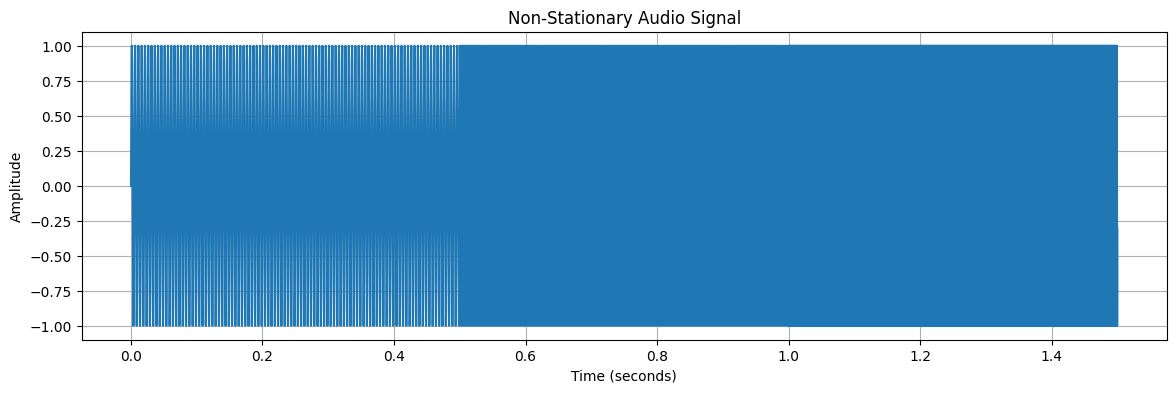

In [3]:
plt.figure(figsize=(14, 4))

plt.plot(t, signal)

plt.title("Non-Stationary Audio Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.grid()
plt.show()

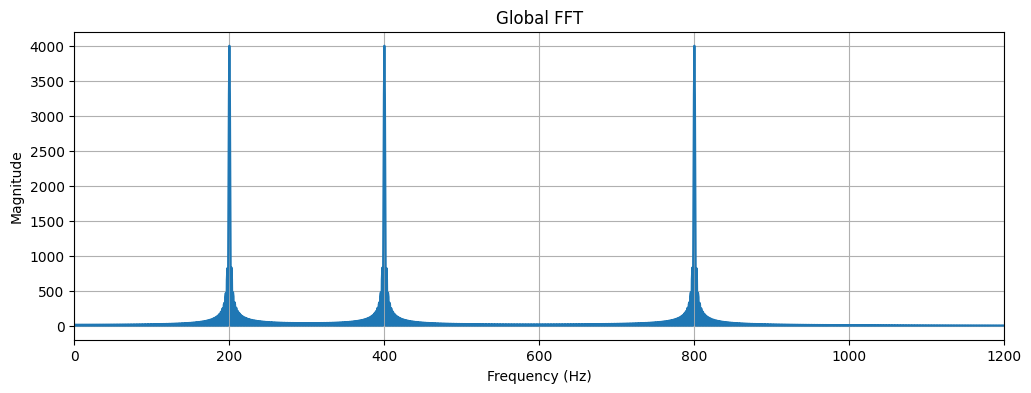

In [4]:
# calculate global fft 

N = len(signal)

X = np.fft.rfft(signal)

frequencies = np.fft.rfftfreq(N, d=1/fs)

magnitude = np.abs(X)

plt.figure(figsize=(12, 4))

plt.plot(frequencies, magnitude)

plt.title("Global FFT")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")

plt.xlim(0, 1200)
plt.grid()
plt.show()

In [5]:
# STFT 

window_length = 400
hop_length = 160

frequencies, times, Zxx = stft(
    signal,
    fs=fs,
    window="hann",
    nperseg=window_length,
    noverlap=window_length - hop_length,
    nfft=window_length,
    boundary=None,
    padded=False
)

In [6]:
magnitude_stft = np.abs(Zxx)

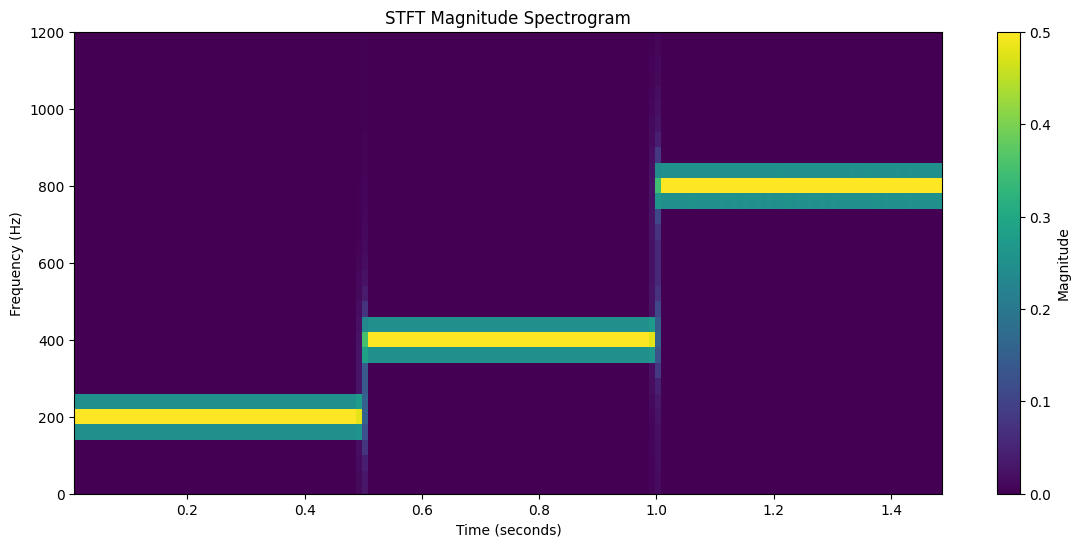

In [7]:
plt.figure(figsize=(14, 6))

plt.pcolormesh(
    times,
    frequencies,
    magnitude_stft,
    shading="auto"
)

plt.title("STFT Magnitude Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

plt.ylim(0, 1200)

plt.colorbar(label="Magnitude")
plt.show()

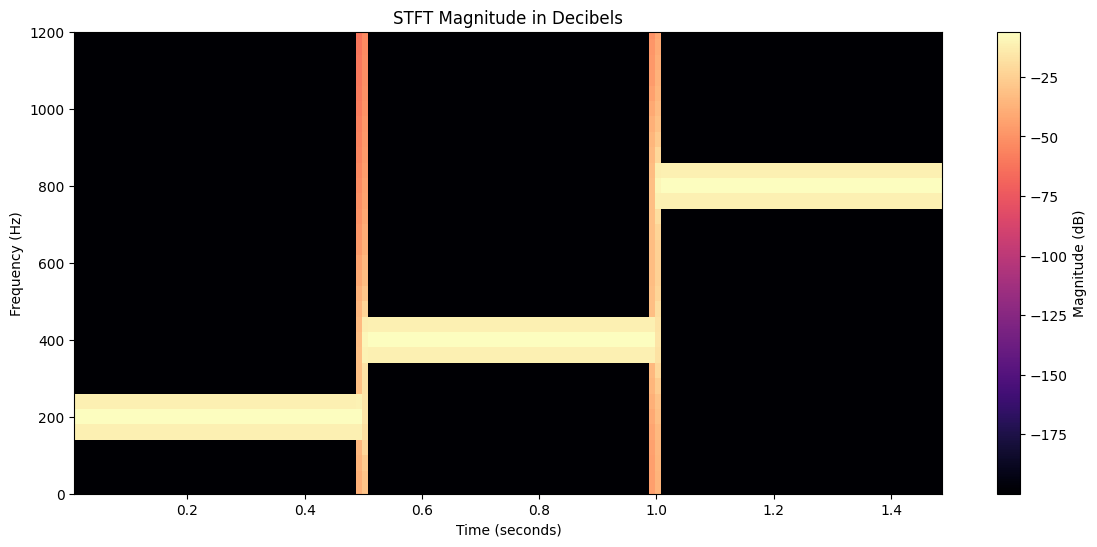

In [8]:
# in decibles 

epsilon = 1e-10

magnitude_db = 20 * np.log10(
    magnitude_stft + epsilon
)

plt.figure(figsize=(14, 6))

plt.pcolormesh(
    times,
    frequencies,
    magnitude_db,
    shading="auto",
    cmap="magma"
)

plt.title("STFT Magnitude in Decibels")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

plt.ylim(0, 1200)

plt.colorbar(label="Magnitude (dB)")
plt.show()

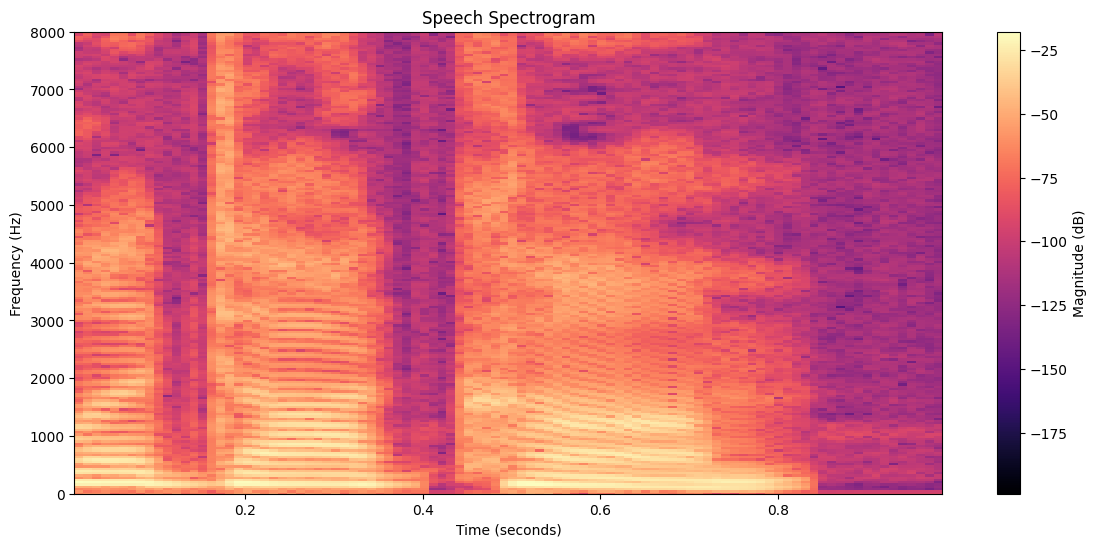

In [18]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import stft

audio, fs = sf.read("audio/raw/sample-speech-1m.mp3")

start = 1 * fs 
end = 2 * fs

if audio.ndim == 2:
    audio = audio.mean(axis=1)

frequencies, times, Zxx = stft(
    audio[start:end],
    fs=fs,
    window="hann",
    nperseg=551,
    noverlap=331,
    nfft=560,
    boundary=None,
    padded=False
)

magnitude = np.abs(Zxx)

magnitude_db = 20 * np.log10(
    magnitude + 1e-10
)

plt.figure(figsize=(14, 6))

plt.pcolormesh(
    times,
    frequencies,
    magnitude_db,
    shading="auto",
    cmap="magma"
)

plt.title("Speech Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

plt.ylim(0, min(8000, fs/2))

plt.colorbar(label="Magnitude (dB)")
plt.show()

In [16]:
fs

22050